# 14 — Calibration: positive control, detectability, G1 and G2

**Stage question.** Can the instrument see a known injected effect, what is the smallest effect it can detect, and does its null hold at β = 0?

| | |
|---|---|
| **Purpose** | Run J3 on the real data's structure with injected targets, before any real result is inspected. Figure 2. |
| **Input** | The analysis data; donors. |
| **Processing** | Y* = f̂(Z) + β·g(A) + ε for β spanning partial R² 0.002-0.05, R replicates each, tested against N1 and N2 nulls; β = 0 for G1. |
| **Output** | `results/j3/<run>/` levels, detectability, G1, G2 verdicts. |
| **Scientific assumptions** | injection settings (replicates, residual resampling, cross map), the G1 rule, the power level and the G2 reporting rule. |
| **Failure modes** | G1 fails: stop and debug, nothing downstream runs. G2 blocked: no bound supplied. |
| **What to look at** | The β = 0 rejection rates with their intervals; the power curve; the MDE. |

**Terms used in this notebook.**

- **Positive control** — a synthetic effect of known size added to real data.
- **MDE** — the smallest injected partial R² detected with the stated power (Bloom 1995).
- **Rejection rate** — the share of replicates whose p-value is at or below α.

> **Before running.** **This is a gate notebook.** State the expectation before running. Expect many hours: it runs across several Colab sessions and resumes where it stopped. G2 is reported, never passed.

In [2]:
# Runtime setup — identical in every notebook.
# Colab: mounts Google Drive and uses MyDrive/coda (a copy of the repository) as
#        the project root, then installs the pinned measurement stack.
# Local: uses the repository checkout.
# Every path used below is relative to that root, so Drive and the repository
# have exactly the same layout and outputs can be copied back unchanged.
import os, sys, subprocess
from pathlib import Path

try:
    from google.colab import drive  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    ROOT = Path(os.environ.get('CODA_ROOT', '/content/drive/MyDrive/coda'))
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r',
                    str(ROOT / 'requirements-colab.txt')], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

os.environ['CODA_ROOT'] = str(ROOT)
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.runtime import runtime_report
REPORT = runtime_report()

Mounted at /content/drive
runtime        colab   python 3.13.18   cpus 2
memory         12.3 GB free of 13.6 GB
gpu            none (not needed for this stage unless stated)
project disk   11.6 GB free   root = /content/drive/MyDrive/coda
scratch disk   93.4 GB free   (audio lives here briefly)
code           fingerprint 9b5146f3ab46b0fc
artifacts      manifest=True, metadata=True, transcripts=True, turns=True, audio_pass_sessions=293, channel_qc=True


**Runtime check.** The cell above prints free disk, memory, CPU, GPU, the code fingerprint and which artifacts already exist. The fingerprint identifies the exact source and configuration that ran and is written into every run record.

In [3]:
STAGE = 'sample'
DATA_KIND = 'sample'
N_DRAWS = 500
STEPS = ['j3_calibration', 'g2']

## Settings

The method settings come from `src/settings.py` (class `Settings`).

In [4]:
from src.settings import Settings
SETTINGS = Settings()

In [5]:
import pandas as pd
from src.paths import paths
from src.experiments.stages import analysis_data
from src.experiments.preflight import preflight, require_preflight
from src.experiments.run_j3 import run_j3
import yaml
P = paths()
data, turns, prosody, split = analysis_data(P, STAGE, 'speaker_disjoint', SETTINGS)
rep = preflight('j3_calibration', DATA_KIND, P.root, split_manifest=split,
                sessions=pd.read_csv(P.manifest, dtype=str)[['session_key', 'participant_key']]
                .drop_duplicates().query('session_key in @split.session_key'),
                compute_estimate={'cpu_hours': '~15 at 112,500 pairs (measured local 4-core); Colab slower', 'resumable': True},
                smoke_test='tests/test_gates_runs_dry_run.py passes')
print(rep.markdown())
require_preflight(rep, DATA_KIND)

/usr/local/lib/python3.13/dist-packages/sentence_transformers/cross_encoder/CrossEncoder.py:11: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm, trange
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (4 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

/content/drive/MyDrive/coda/src/data/dataset.py:180: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False).astype(bool),


# Preflight — `j3_calibration` on `sample` data

**Result: PASS**

| Check | Result | Critical | Detail |
|---|---|---|---|
| integrity suite passed for this code | ok | yes | 303 tests, 0 failures, 0 errors, 0 skipped (20261025T053747Z) |
| split manifest valid | ok | yes | speaker-disjoint; every session assigned |
| compute estimate recorded | ok | yes | {"cpu_hours": "~15 at 112,500 pairs (measured local 4-core); Colab slower", "resumable": true} |
| smoke test defined | ok | yes | tests/test_gates_runs_dry_run.py passes |

**code_fingerprint.** `"9b5146f3ab46b0fc"`



In [6]:
targets = P.load_config("j3_injection")["injection"]["beta_targets_partial_r2"]

n_levels = 1 + 2 * len(targets)

print("Number of beta targets:", len(targets))
print("Total levels:", n_levels)
print("Last level index:", n_levels - 1)
print(f"Expected final checkpoint: j3_level_{n_levels-1:02d}_c000.json")
print("Expected total checkpoint files:", 8 + 2 * len(targets))

Number of beta targets: 7
Total levels: 15
Last level index: 14
Expected final checkpoint: j3_level_14_c000.json
Expected total checkpoint files: 22


In [7]:
from pathlib import Path
import json

# Locate CODA results
results_root = Path("/content/drive/MyDrive/coda/results")

# Find J3 run directories containing calibration checkpoints
runs = sorted(
    [p for p in results_root.rglob("*") if p.is_dir()
     and any(p.glob("j3_level_*_c*.json"))],
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

if not runs:
    print("No J3 checkpoint files found yet.")
else:
    run_dir = runs[0]
    checkpoints = sorted(run_dir.glob("j3_level_*_c*.json"))

    # Read the run configuration to estimate expected checkpoint count
    config_files = list(run_dir.glob("*config*.json"))
    print(f"Run directory: {run_dir}")
    print(f"Completed checkpoint files: {len(checkpoints)}")

    # Show checkpoint files and their sizes
    for f in checkpoints:
        print(f"  {f.name:35} {f.stat().st_size / 1024:.1f} KB")

    # Check whether final-stage outputs exist
    print("\nFinal-stage files:")
    for name in ["j3_levels.json", "gate_G1.json",
                 "detectability.json", "gate_G2.json"]:
        print(f"  {name}: {'YES' if (run_dir / name).exists() else 'not found yet'}")

Run directory: /content/drive/MyDrive/coda/results/j3/sample__sample__m55a87f6ee7__s19379138530a__719af2298ec13413
Completed checkpoint files: 15
  j3_level_00_c000.json               90.2 KB
  j3_level_00_c001.json               90.3 KB
  j3_level_00_c002.json               90.3 KB
  j3_level_00_c003.json               90.2 KB
  j3_level_00_c004.json               90.5 KB
  j3_level_00_c005.json               90.4 KB
  j3_level_00_c006.json               90.5 KB
  j3_level_00_c007.json               90.5 KB
  j3_level_01_c000.json               18.9 KB
  j3_level_02_c000.json               18.9 KB
  j3_level_03_c000.json               18.7 KB
  j3_level_04_c000.json               18.7 KB
  j3_level_05_c000.json               18.6 KB
  j3_level_06_c000.json               18.6 KB
  j3_level_07_c000.json               18.6 KB

Final-stage files:
  j3_levels.json: not found yet
  gate_G1.json: not found yet
  detectability.json: not found yet
  gate_G2.json: not found yet


In [8]:
from pathlib import Path
from datetime import datetime

checkpoint_files = sorted(
    Path(P.results).rglob("j3_level_*_c*.json"),
    key=lambda p: p.stat().st_mtime,
)

for p in checkpoint_files[-10:]:
    timestamp = datetime.fromtimestamp(p.stat().st_mtime)
    print(timestamp, p.name, f"{p.stat().st_size:,} bytes")

2026-10-26 14:10:56 j3_level_00_c005.json 92,597 bytes
2026-10-28 14:28:59 j3_level_00_c006.json 92,693 bytes
2026-10-28 16:50:55 j3_level_00_c007.json 92,699 bytes
2026-10-28 17:29:07 j3_level_01_c000.json 19,391 bytes
2026-10-28 18:07:14 j3_level_02_c000.json 19,320 bytes
2026-10-28 18:44:48 j3_level_03_c000.json 19,192 bytes
2026-10-28 19:22:23 j3_level_04_c000.json 19,115 bytes
2026-10-28 19:59:56 j3_level_05_c000.json 19,068 bytes
2026-10-28 20:37:22 j3_level_06_c000.json 19,025 bytes
2026-10-28 21:14:46 j3_level_07_c000.json 18,998 bytes


In [ ]:
targets = P.load_config('j3_injection')['injection']['beta_targets_partial_r2']
j3_dir, j3 = run_j3(data, turns, prosody, results_root=P.results, data_kind=DATA_KIND,
                    stage=STAGE, n_draws=N_DRAWS, targets=targets, settings=SETTINGS,
                    preflight_report=rep, resume=True)   # re-run this cell after a disconnect
print('G1:', j3['G1'].status, j3['G1'].evidence['rates'])
print('G2:', j3['G2'].status, j3['mde'])

G1: FAIL {'N1': {'rate': 0.088, 'rejections': 176, 'replicates': 2000, 'ci95': [0.07594517775871472, 0.10127788287047298]}, 'N2': {'rate': 0.0935, 'rejections': 187, 'replicates': 2000, 'ci95': [0.0810937947727658, 0.10711211374592862]}}
G2: NOT_EVALUATED {'aggregate': 0.002, 'aggregate_target_scale': 0.002, 'aggregate_realised_scale': 0.0017306841786716549, 'block': [0.002, 0.002, 0.002, 0.002], 'power_level': 0.8, 'coupling': 'identity_matched_dimensions', 'rule': 'the larger of the target-scale and realised-scale MDE'}


PosixPath('/content/drive/MyDrive/coda/figures/14_calibration/figure2_detectability.png')

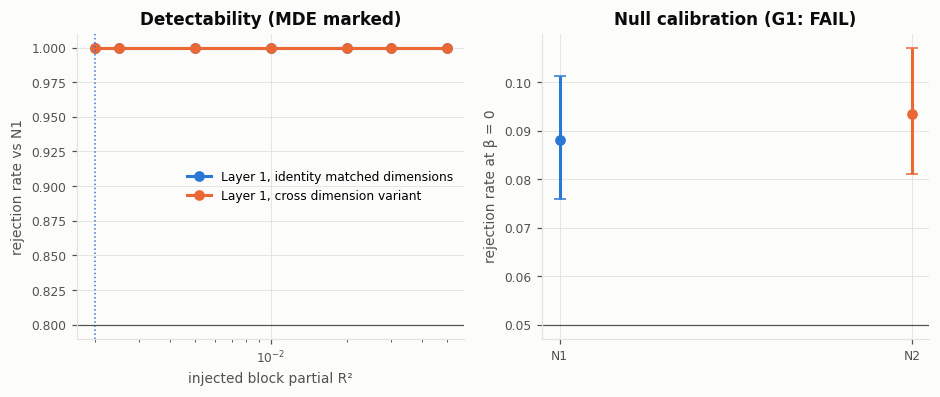

In [ ]:
from src.viz import figures, style
style.apply()
fig = figures.figure2_detectability(j3_dir)
style.save(fig, P.figures, '14_calibration', 'figure2_detectability')

**How to read the outputs.** G1: for N1 and for N2, the one-sided 95% upper bound of the β = 0 rejection rate must be at most 0.075 (Bradley's liberal criterion, 2,000 replicates). With 500 donor draws the test's exact size is 26/501 = 0.0519, so a rate near 0.052 is expected from a valid null. A G1 FAIL stops everything downstream; never re-run with new seeds after a failure. The power curve rises with the injected effect, and the MDE is where it crosses power 0.80. G2 is reported, not passed: state the MDE, and power at 0.0025, 0.005 and 0.01, which are sensitivity values, not thresholds. **Resuming:** each chunk of replicates is saved as it completes. After a disconnect, re-run the setup cells and this cell; finished chunks are skipped and the numbers are unchanged.